<a href="https://colab.research.google.com/github/Sands225/Gallstone-Classification/blob/main/%5BMachine_Learning%5D_Gallstone_Disease_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Kelompok 5: Gallstone Classification

**Mata Kuliah** : \
Machine Learning A

\
**Dosen Pengampu** :  \
Dr. Ir. I Wayan Agus Surya Darma, S.Kom., M.T.

\
**Anggota Kelompok**:
| NIM | Nama |
| --- | --- |
| 2405551007 | I Gusti Bagus Narendratanaya Wiweka |
| 2405551026 | I Putu Raditya Dharma Yoga |
| 2405551025 | I Gde Made Fajar Harry Putra Utama |
| 2405551056 | Anak Agung Ngurah Figo Laksmana Saputra |
| 2405551082 | I Made Sandika Wijaya |

In [ ]:
!pip -q install xgboost lightgbm shap

In [ ]:
import pandas as pd
import numpy as np
from google.colab import drive
import os
import math
import shap

import seaborn as sns
import matplotlib.pyplot as plt
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

from scipy.stats import chi2_contingency
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder
from sklearn.compose import ColumnTransformer

from sklearn.model_selection import train_test_split

from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.ensemble import (
  RandomForestClassifier,
  ExtraTreesClassifier,
  GradientBoostingClassifier,
  VotingClassifier,
  StackingClassifier
)
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import (
  accuracy_score,
  precision_score,
  recall_score,
  f1_score,
  roc_auc_score,
  brier_score_loss,
  classification_report,
  confusion_matrix,
  ConfusionMatrixDisplay
)

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

## Data Collection

In [ ]:
try:
  df = pd.read_csv('/content/dataset-uci.csv', sep=None, engine='python', decimal=',')
  print("Dataset berhasil dibaca dari local Colab.")

except Exception as e:
  try:
    if not os.path.exists('/content/drive/MyDrive'):
      drive.mount('/content/drive')

    df = pd.read_csv('/content/drive/MyDrive/College/Machine Learning/gallstone_dataset/dataset-uci.csv')
    print("Dataset berhasil dibaca dari Google Drive.")

  except Exception as e:
        print(f"Gagal membaca dari Google Drive: {e}")

df.head()

Dataset berhasil dibaca dari Google Drive.


,Gallstone Status,Age,Gender,Comorbidity,Coronary Artery Disease (CAD),Hypothyroidism,Hyperlipidemia,Diabetes Mellitus (DM),Height,Weight,...,High Density Lipoprotein (HDL),Triglyceride,Aspartat Aminotransferaz (AST),Alanin Aminotransferaz (ALT),Alkaline Phosphatase (ALP),Creatinine,Glomerular Filtration Rate (GFR),C-Reactive Protein (CRP),Hemoglobin (HGB),Vitamin D
0,0,50,0,0,0,0,0,0,185,92.8,...,40.0,134.0,20.0,22.0,87.0,0.82,112.47,0.0,16.0,33.0
1,0,47,0,1,0,0,0,0,176,94.5,...,43.0,103.0,14.0,13.0,46.0,0.87,107.10,0.0,14.4,25.0
2,0,61,0,0,0,0,0,0,171,91.1,...,43.0,69.0,18.0,14.0,66.0,1.25,65.51,0.0,16.2,30.2
3,0,41,0,0,0,0,0,0,168,67.7,...,59.0,53.0,20.0,12.0,34.0,1.02,94.10,0.0,15.4,35.4
4,0,42,0,0,0,0,0,0,178,89.6,...,30.0,326.0,27.0,54.0,71.0,0.82,112.47,0.0,16.8,40.6


## Exploratory Data Analysis (EDA)


Exploratory Data Analysis atau EDA dilakukan dengan tahapan sebagai berikut.
1. Membagi dataset ke dalam `categorical` features dan `numerical` features
2. Melihat informasi numerical dan categorical features
3. Analisis Distribusi dan Skewness
4. Analisis Outlier
5. Analisis Korelasi Fitur dengan `Pearson Correlation`
6. Analisis Variable Influence Factor (VIF)
7. Analisis Asosiasi menggunakan `Cramér’s V`

In [ ]:
# Membagi DataFrame berdasarkan tipe data
cat_cols = [
  'Gender',
  'Comorbidity',
  'Coronary Artery Disease (CAD)',
  'Hypothyroidism',
  'Hyperlipidemia',
  'Diabetes Mellitus (DM)',
  'Hepatic Fat Accumulation (HFA)',
  'Gallstone Status'
]

num_cols = [col for col in df.columns if col not in cat_cols]

print(f"Jumlah Categorical Features: {len(cat_cols)}")
print(f"Jumlah Numerical Features: {len(num_cols)}\n")

print("Categorical Features:")
for col in cat_cols:
  print(col)

print("\nNumerical Features:")
for col in num_cols:
  print(col)

Jumlah Categorical Features: 8
Jumlah Numerical Features: 31

Categorical Features:
Gender
Comorbidity
Coronary Artery Disease (CAD)
Hypothyroidism
Hyperlipidemia
Diabetes Mellitus (DM)
Hepatic Fat Accumulation (HFA)
Gallstone Status

Numerical Features:
Age
Height
Weight
Body Mass Index (BMI)
Total Body Water (TBW)
Extracellular Water (ECW)
Intracellular Water (ICW)
Extracellular Fluid/Total Body Water (ECF/TBW)
Total Body Fat Ratio (TBFR) (%)
Lean Mass (LM) (%)
Body Protein Content (Protein) (%)
Visceral Fat Rating (VFR)
Bone Mass (BM)
Muscle Mass (MM)
Obesity (%)
Total Fat Content (TFC)
Visceral Fat Area (VFA)
Visceral Muscle Area (VMA) (Kg)
Glucose
Total Cholesterol (TC)
Low Density Lipoprotein (LDL)
High Density Lipoprotein (HDL)
Triglyceride
Aspartat Aminotransferaz (AST)
Alanin Aminotransferaz (ALT)
Alkaline Phosphatase (ALP)
Creatinine
Glomerular Filtration Rate (GFR)
C-Reactive Protein (CRP)
Hemoglobin (HGB)
Vitamin D


In [ ]:
# Informasi Numerical Features
print("=== NUMERICAL FEATURES ===")
print(f"Jumlah fitur: {len(num_cols)}")

display(df[num_cols].describe().T)

# Informasi Categorical Features
print("\n=== CATEGORICAL FEATURES ===")
print(f"Jumlah fitur: {len(cat_cols)}")

cat_info = pd.DataFrame({
  'Data Type': df[cat_cols].dtypes.astype(str),
  'Missing Values': df[cat_cols].isnull().sum(),
  'Unique Values': df[cat_cols].nunique(),
  'Categories': [
    df[col].dropna().unique().tolist()
    for col in cat_cols
  ]
})

display(cat_info)

=== NUMERICAL FEATURES ===
Jumlah fitur: 31


,count,mean,std,min,25%,50%,75%,max
Age,319.0,48.068966,12.114558,20.00,38.500,49.000000,56.000,96.00
Height,319.0,167.156740,10.053030,145.00,159.500,168.000000,175.000,191.00
Weight,319.0,80.564890,15.709069,42.90,69.600,78.800000,91.250,143.50
Body Mass Index (BMI),319.0,28.877116,5.313707,17.40,25.250,28.300000,31.850,49.70
Total Body Water (TBW),319.0,40.587774,7.930235,13.00,34.200,39.800000,47.000,66.20
Extracellular Water (ECW),319.0,17.071160,3.161857,9.00,14.800,17.100000,19.400,27.80
Intracellular Water (ICW),319.0,23.634483,5.349332,13.80,19.300,23.000000,27.550,57.10
Extracellular Fluid/Total Body Water (ECF/TBW),319.0,42.212038,3.244470,29.23,40.075,42.000000,44.000,52.00
Total Body Fat Ratio (TBFR) (%),319.0,28.274984,8.444417,6.30,22.025,27.820000,34.810,50.92
Lean Mass (LM) (%),319.0,71.638245,8.437598,48.99,65.165,72.110000,77.850,93.67



=== CATEGORICAL FEATURES ===
Jumlah fitur: 8


,Data Type,Missing Values,Unique Values,Categories
Gender,int64,0,2,"[0, 1]"
Comorbidity,int64,0,4,"[0, 1, 3, 2]"
Coronary Artery Disease (CAD),int64,0,2,"[0, 1]"
Hypothyroidism,int64,0,2,"[0, 1]"
Hyperlipidemia,int64,0,2,"[0, 1]"
Diabetes Mellitus (DM),int64,0,2,"[0, 1]"
Hepatic Fat Accumulation (HFA),int64,0,5,"[0, 1, 2, 3, 4]"
Gallstone Status,int64,0,2,"[0, 1]"


In [ ]:
# Analisis Distribusi dan Skewness
skew_df = pd.DataFrame({
  'Feature': num_cols,
  'Skewness': df[num_cols].skew().values
})

skew_df['Distribution'] = skew_df['Skewness'].apply(
  lambda x: 'Right-skewed' if x > 0.5
  else ('Left-skewed' if x < -0.5 else 'Approximately symmetric')
)

display(
  skew_df.sort_values('Skewness', key=abs, ascending=False)
)

,Feature,Skewness,Distribution
14,Obesity (%),16.873233,Right-skewed
24,Alanin Aminotransferaz (ALT),7.276949,Right-skewed
23,Aspartat Aminotransferaz (AST),6.994506,Right-skewed
21,High Density Lipoprotein (HDL),6.528948,Right-skewed
18,Glucose,5.937810,Right-skewed
28,C-Reactive Protein (CRP),5.411104,Right-skewed
22,Triglyceride,2.786394,Right-skewed
27,Glomerular Filtration Rate (GFR),-1.812975,Left-skewed
16,Visceral Fat Area (VFA),1.057540,Right-skewed
6,Intracellular Water (ICW),0.952158,Right-skewed


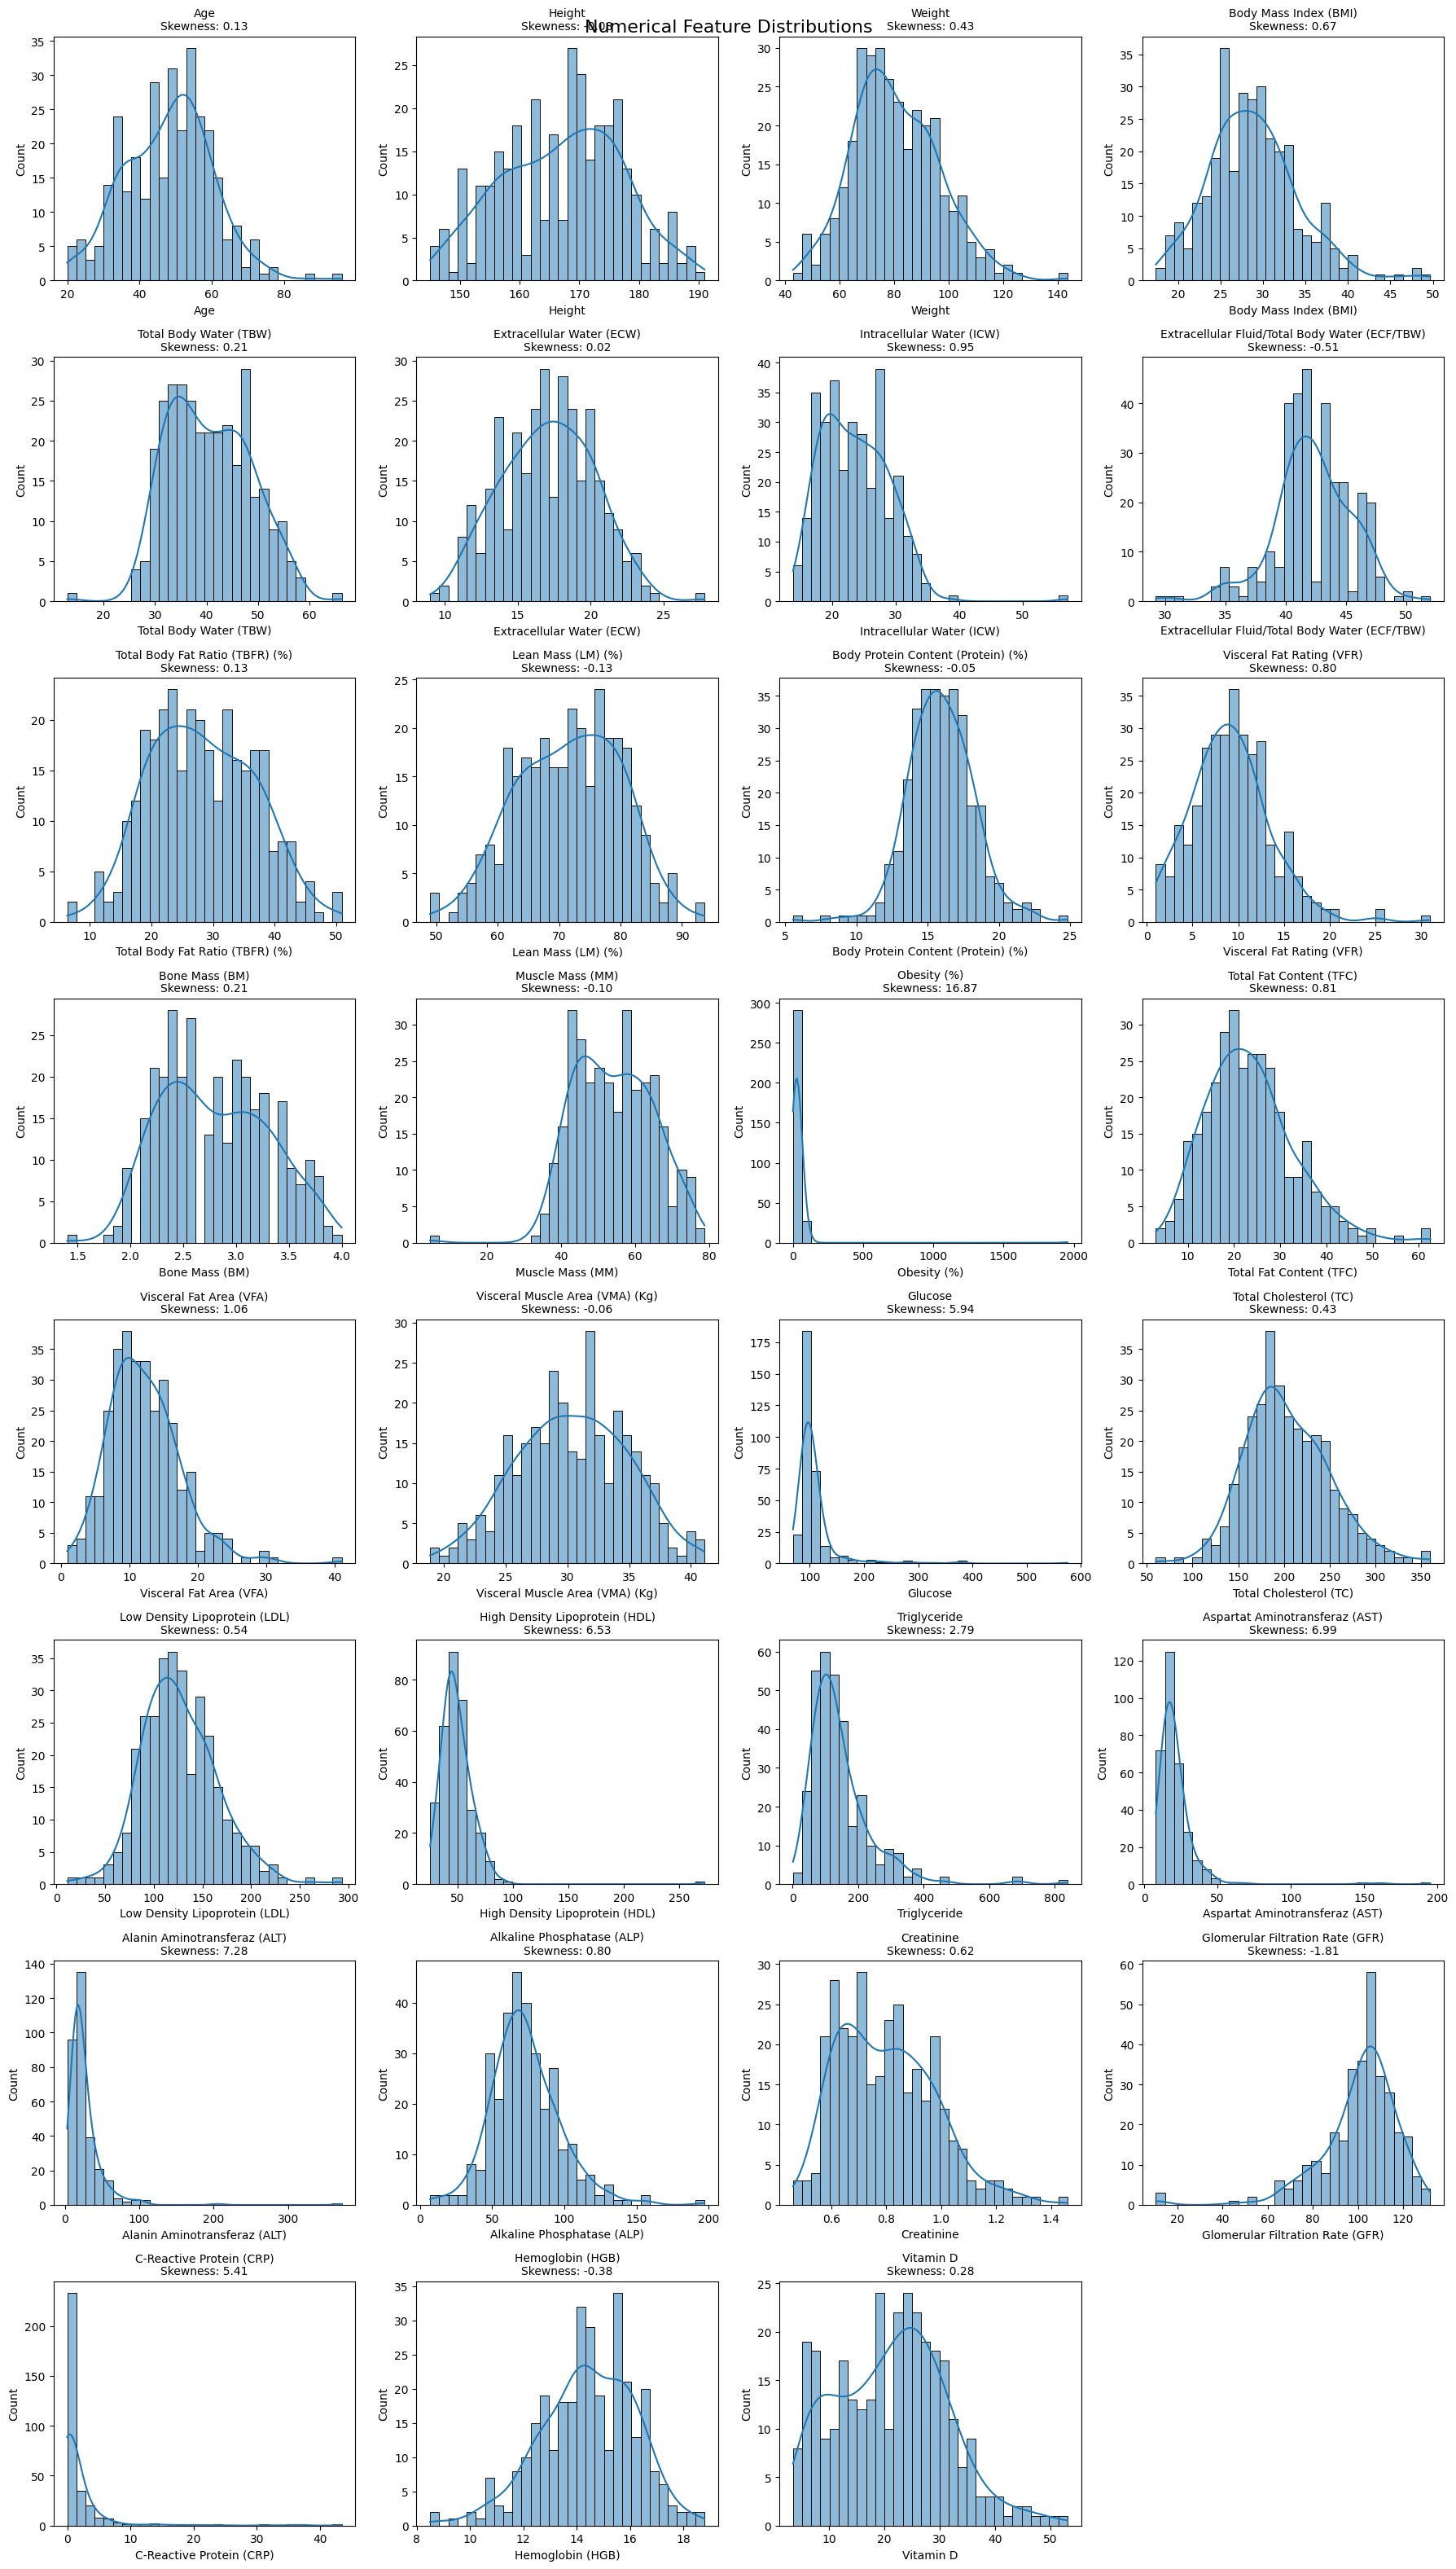

In [ ]:
# Visualisasi Distribusi Fitur Numerik
cols_per_row = 4
n_rows = math.ceil(len(num_cols) / cols_per_row)

fig, axes = plt.subplots(
  n_rows, cols_per_row,
  figsize=(18, n_rows * 4)
)

axes = axes.flatten()

for i, col in enumerate(num_cols):
  sns.histplot(df[col].dropna(), kde=True, bins=30, ax=axes[i])
  axes[i].set_title(f'{col}\nSkewness: {df[col].skew():.2f}', fontsize=10)

for i in range(len(num_cols), len(axes)):
  axes[i].set_visible(False)

plt.suptitle('Numerical Feature Distributions', fontsize=16)
plt.tight_layout()
plt.show()

In [ ]:
# Analisis Outlier
outlier_results = []

for col in num_cols:
  Q1 = df[col].quantile(0.25)
  Q3 = df[col].quantile(0.75)
  IQR = Q3 - Q1

  lower = Q1 - 1.5 * IQR
  upper = Q3 + 1.5 * IQR

  outliers = df[col].notna() & (
    (df[col] < lower) | (df[col] > upper)
  )

  outlier_results.append({
    'Feature': col,
    'Lower Bound': lower,
    'Upper Bound': upper,
    'Outlier Count': outliers.sum(),
    'Outlier (%)': outliers.sum() / df[col].notna().sum() * 100
    if df[col].notna().sum() > 0 else np.nan
  })

outlier_df = pd.DataFrame(outlier_results)

outlier_df = outlier_df.sort_values(
  'Outlier Count',
  ascending=False
).reset_index(drop=True)

display(outlier_df.round(2))

,Feature,Lower Bound,Upper Bound,Outlier Count,Outlier (%)
0,C-Reactive Protein (CRP),-2.42,4.04,34,10.66
1,Alanin Aminotransferaz (ALT),-9.38,53.62,27,8.46
2,Glucose,66.50,134.50,25,7.84
3,Aspartat Aminotransferaz (AST),3.00,35.00,23,7.21
4,Triglyceride,-50.50,305.50,20,6.27
5,Glomerular Filtration Rate (GFR),69.31,135.61,13,4.08
6,Alkaline Phosphatase (ALP),16.00,128.00,12,3.76
7,Body Protein Content (Protein) (%),10.02,21.88,8,2.51
8,Total Fat Content (TFC),-0.33,45.88,7,2.19
9,Extracellular Fluid/Total Body Water (ECF/TBW),34.19,49.89,7,2.19


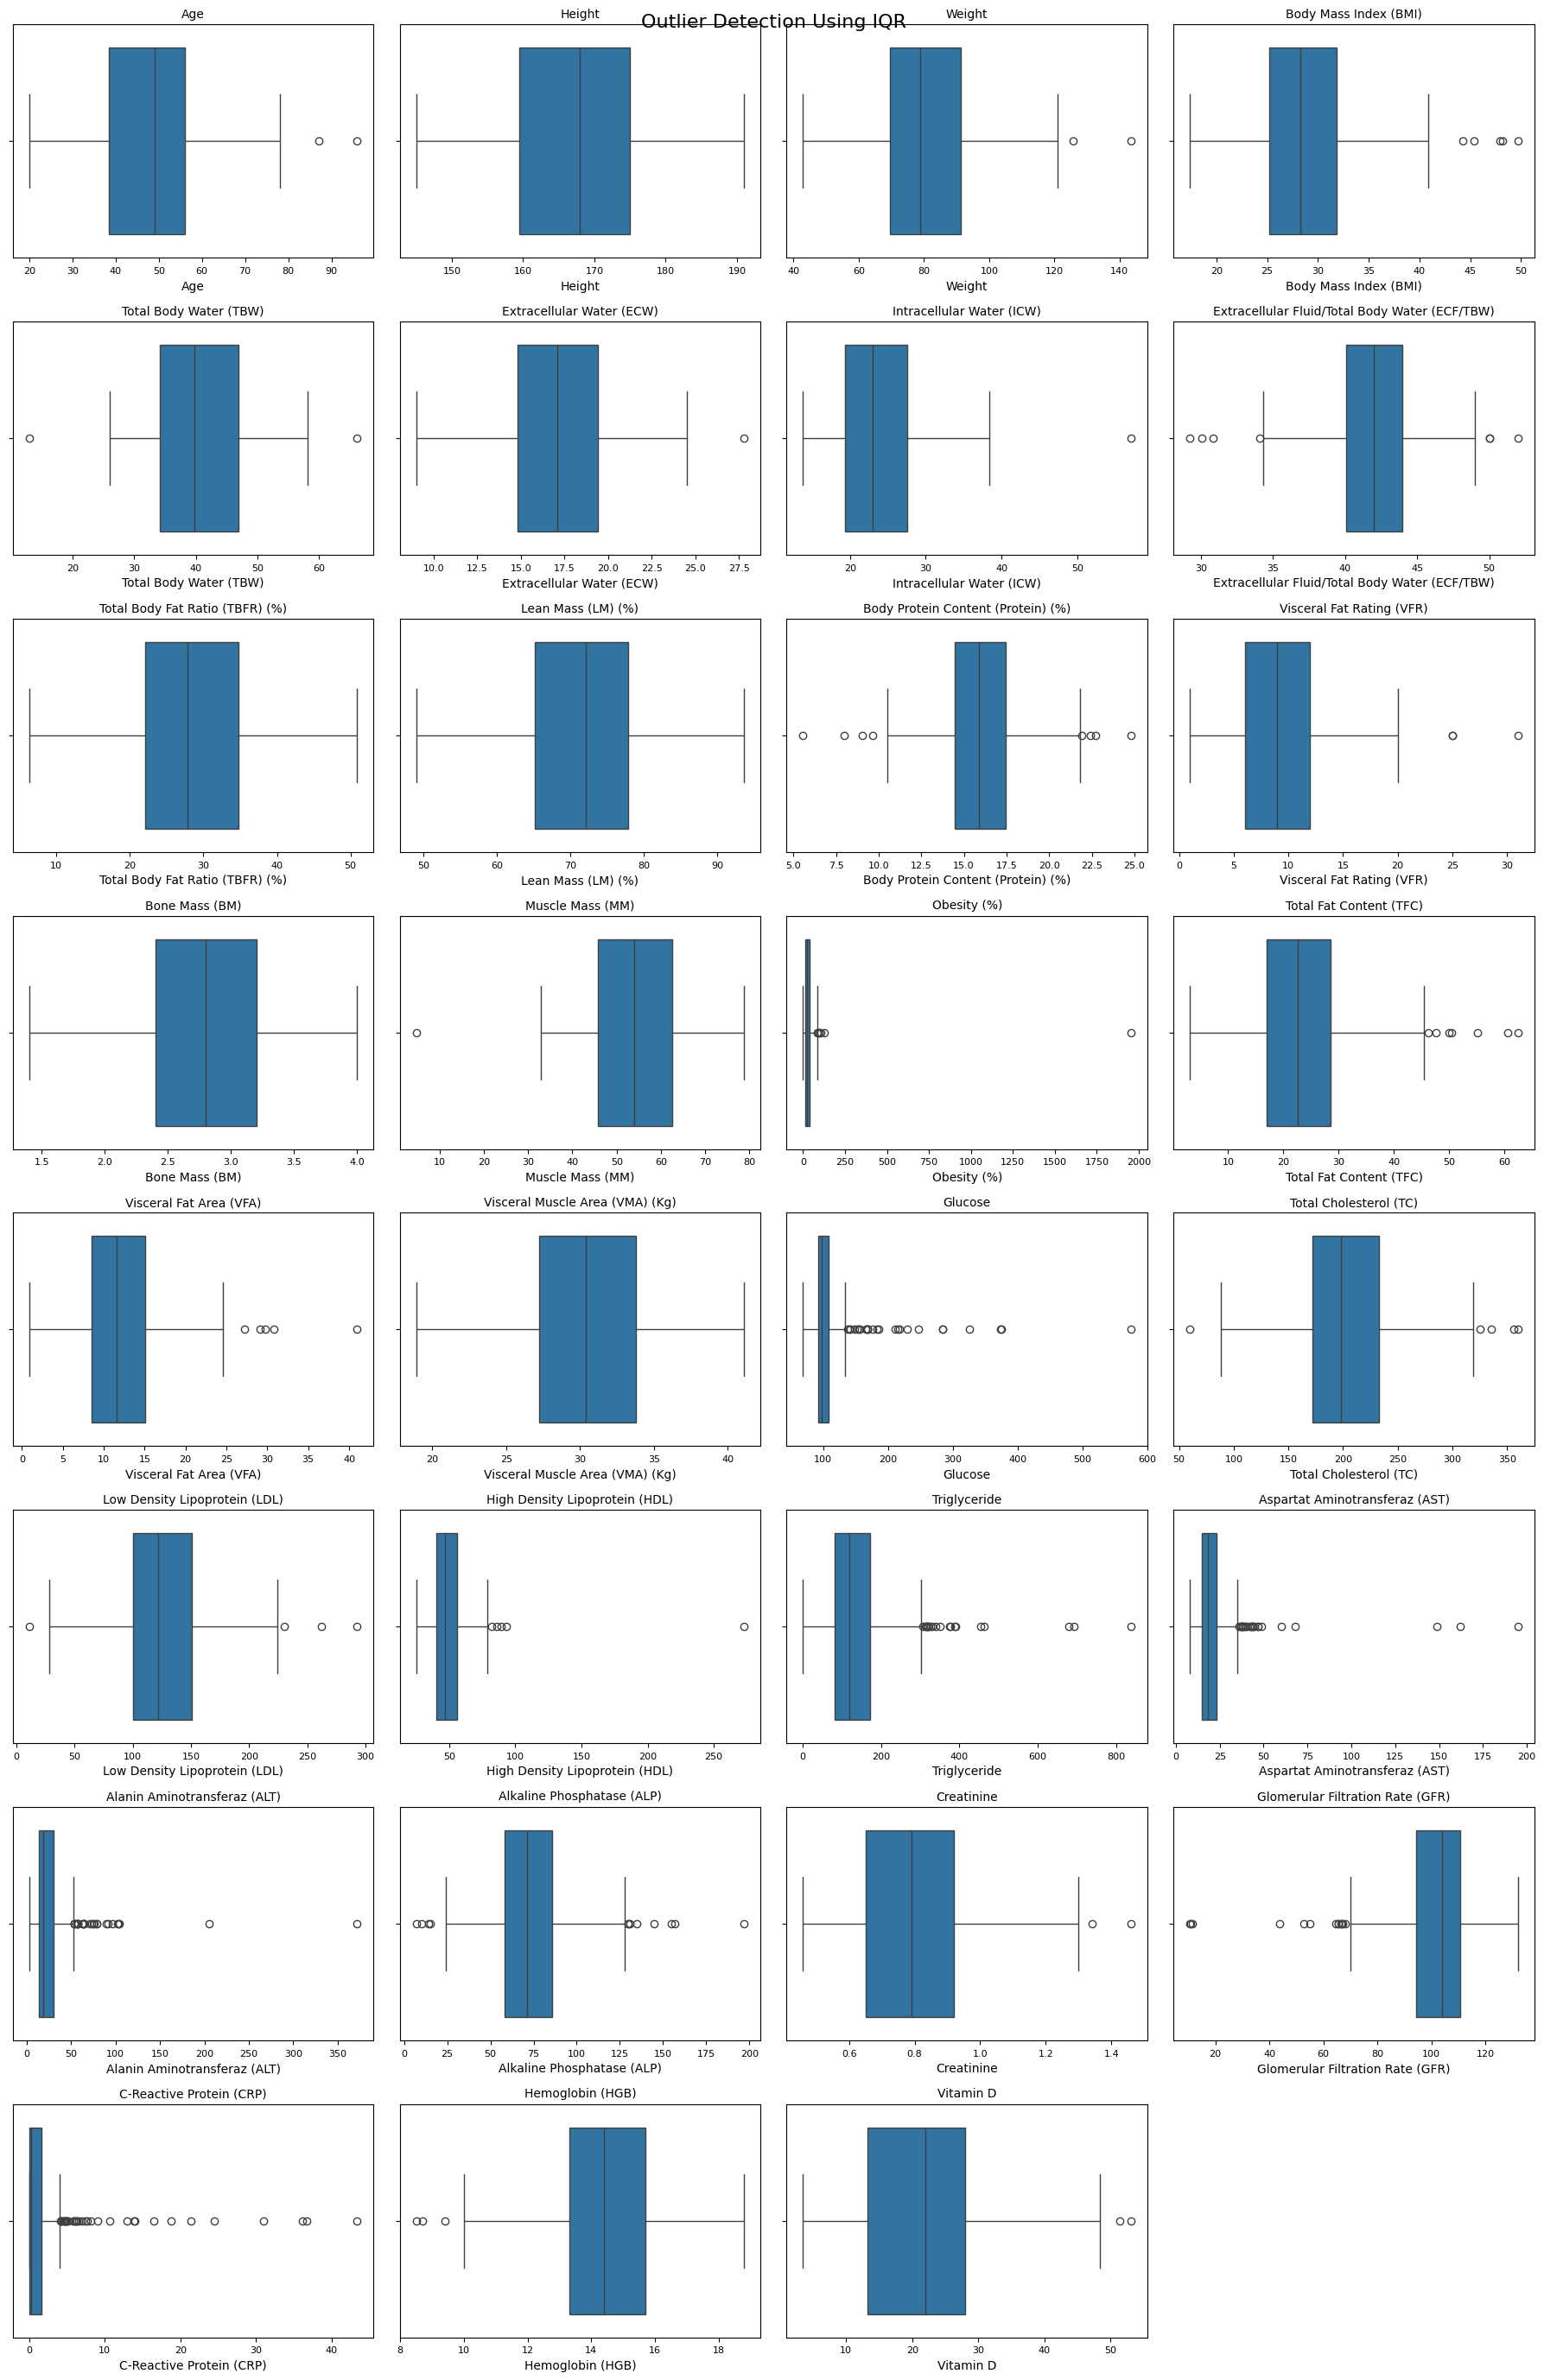

In [ ]:
# Visualisasi Outlier
cols_per_row = 4
n_rows = math.ceil(len(num_cols) / cols_per_row)

fig, axes = plt.subplots(
    n_rows,
    cols_per_row,
    figsize=(18, n_rows * 3.5)
)

axes = np.array(axes).flatten()

for i, col in enumerate(num_cols):
    sns.boxplot(x=df[col], ax=axes[i])
    axes[i].set_title(col, fontsize=10)
    axes[i].tick_params(axis='x', labelsize=8)

for i in range(len(num_cols), len(axes)):
    axes[i].set_visible(False)

plt.suptitle('Outlier Detection Using IQR', fontsize=16)
plt.tight_layout()
plt.show()

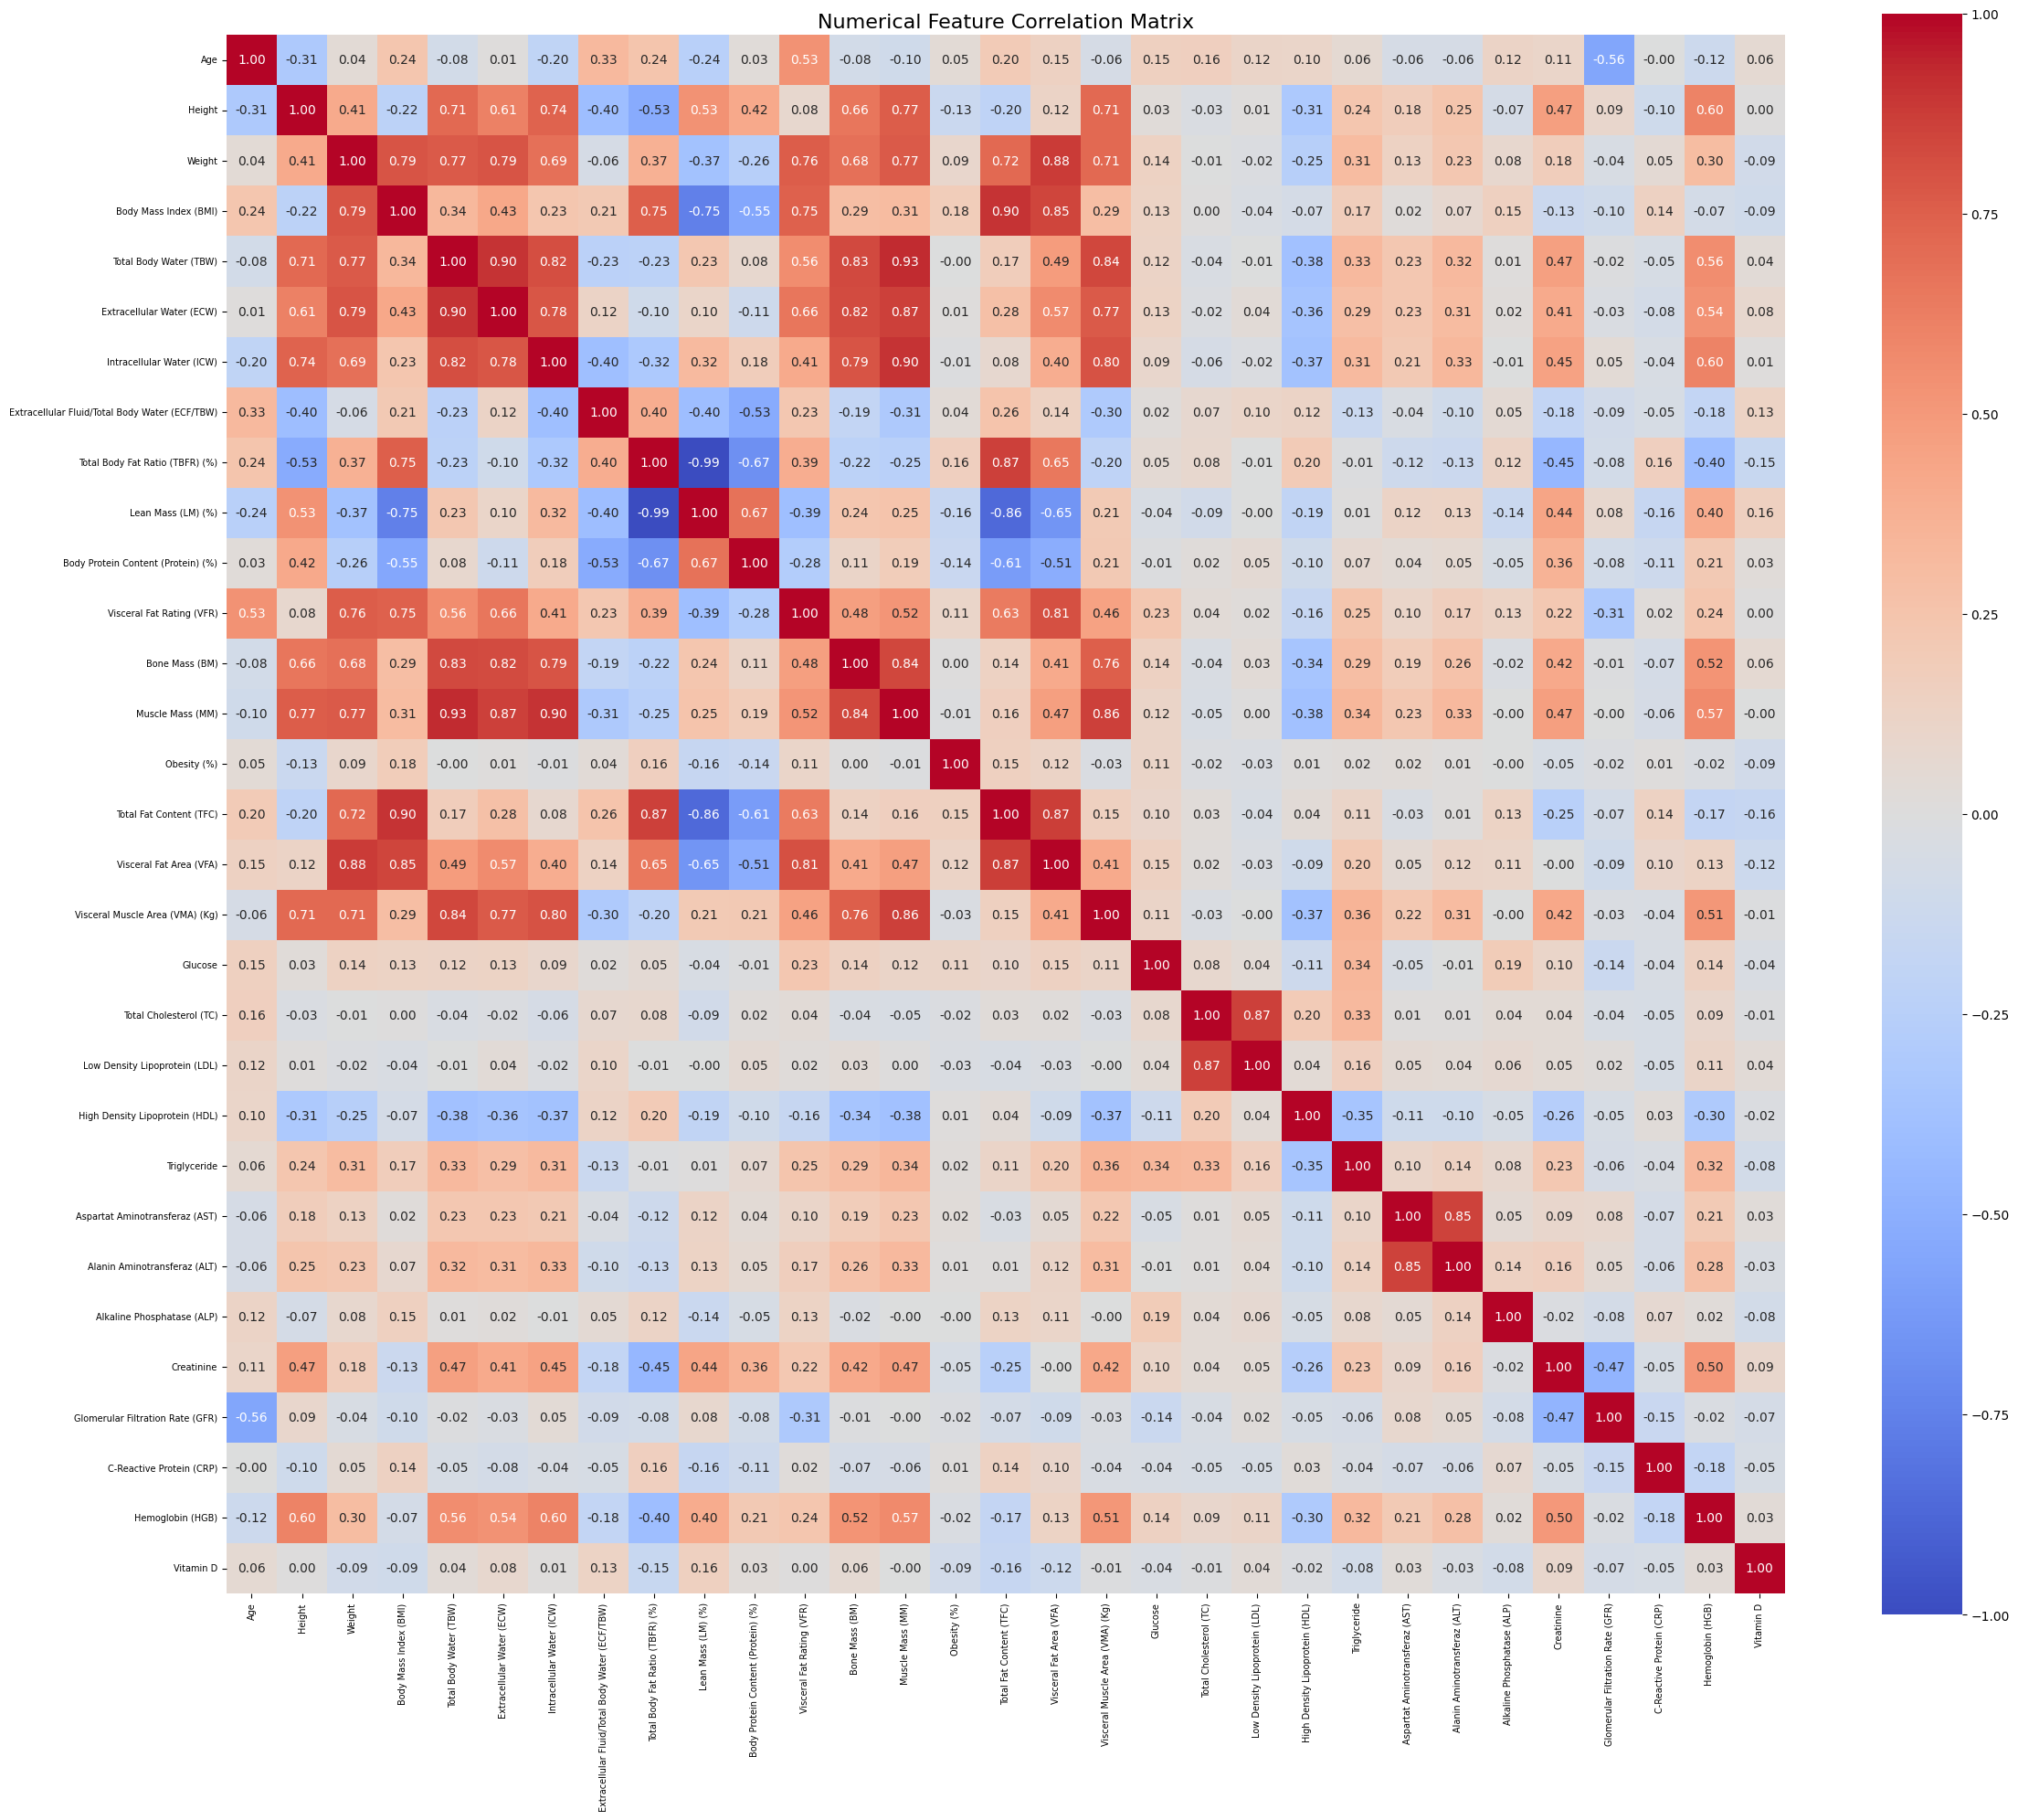

Pasangan fitur dengan korelasi absolut > 0.95:
Total Body Fat Ratio (TBFR) (%) <=> Lean Mass (LM) (%): 0.9941 (99.41%)


In [ ]:
# Analisis Korelasi Fitur
corr = df[num_cols].corr()

# Heatmap
plt.figure(figsize=(24, 20))

sns.heatmap(
  corr,
  annot=True,
  fmt='.2f',
  cmap='coolwarm',
  vmin=-1,
  vmax=1,
  center=0,
  square=True,
  annot_kws={'size': 10}
)

plt.title('Numerical Feature Correlation Matrix', fontsize=16)
plt.xticks(rotation=90, fontsize=7)
plt.yticks(rotation=0, fontsize=7)
plt.tight_layout()
plt.show()

# Mencari pasangan fitur dengan korelasi > 0.95
upper = corr.abs().where(
    np.triu(np.ones(corr.shape), k=1).astype(bool)
)

print("Pasangan fitur dengan korelasi absolut > 0.95:")
found = False
for col in upper.columns:
  for row in upper.index:
    value = upper.loc[row, col]

    if pd.notna(value) and value > 0.95:
      print(f"{row} <=> {col}: {value:.4f} ({value*100:.2f}%)")
      found = True

if not found:
  print("Tidak ada pasangan fitur dengan korelasi > 0.95.")

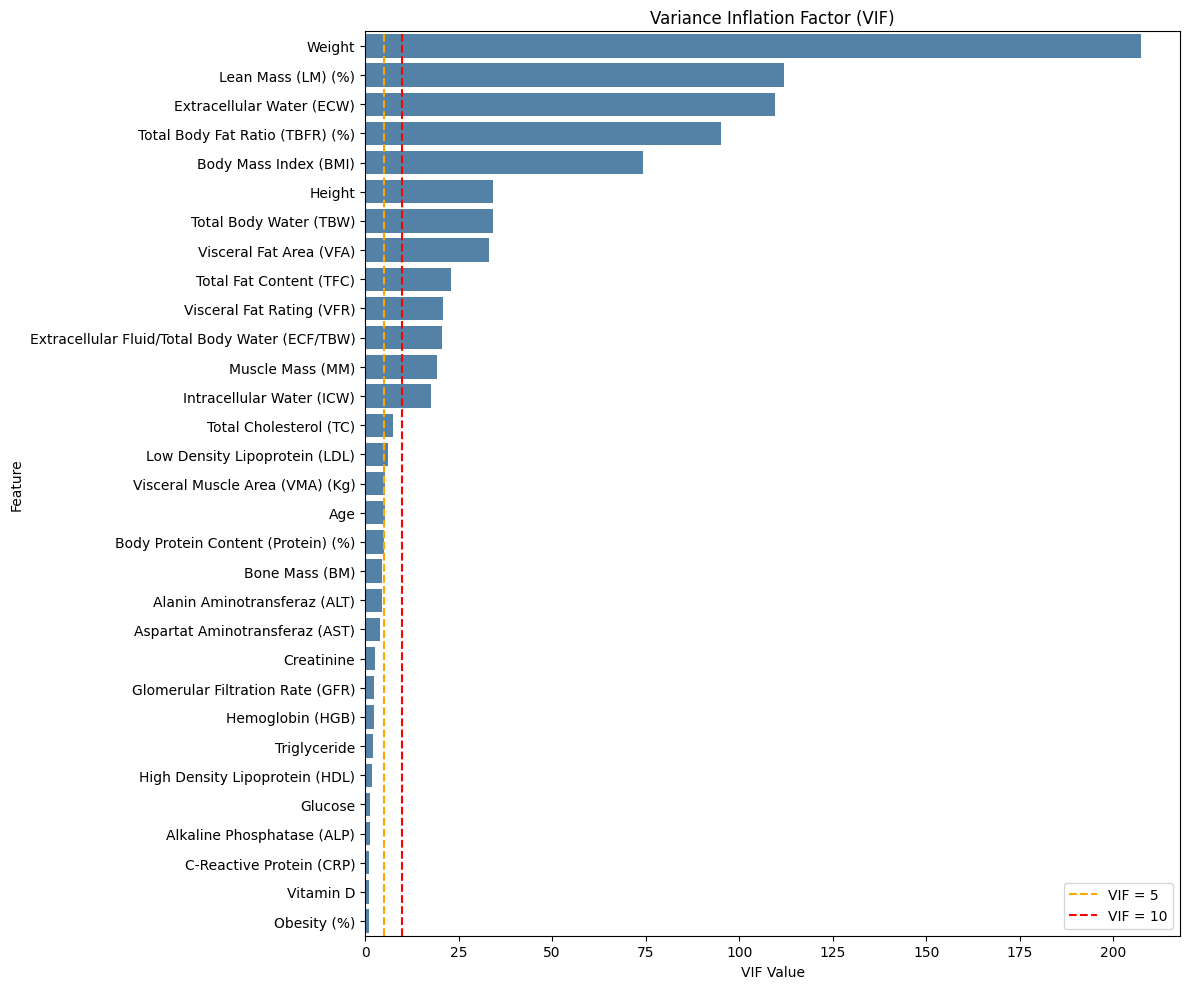

In [ ]:
# Persiapan data
X_vif = df[num_cols].dropna().copy()
X_vif = X_vif.loc[:, X_vif.nunique() > 1]

# Hitung VIF
X_const = add_constant(X_vif)

vif_df = pd.DataFrame({
  'Feature': X_vif.columns,
  'VIF': [
    variance_inflation_factor(X_const.values, i + 1)
    for i in range(len(X_vif.columns))
  ]
}).sort_values('VIF', ascending=False)

# Visualisasi
plt.figure(figsize=(12, 10))

sns.barplot(
  data=vif_df,
  x='VIF',
  y='Feature',
  color='steelblue'
)

plt.axvline(5, color='orange', linestyle='--', label='VIF = 5')
plt.axvline(10, color='red', linestyle='--', label='VIF = 10')

plt.title('Variance Inflation Factor (VIF)')
plt.xlabel('VIF Value')
plt.ylabel('Feature')
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
def cramers_v(x, y):
  table = pd.crosstab(x, y)

  if min(table.shape) < 2:
    return np.nan

  chi2 = chi2_contingency(table, correction=False)[0]
  n = table.to_numpy().sum()
  r, k = table.shape

  return np.sqrt(chi2 / (n * min(r - 1, k - 1)))

# Membuat association matrix
cramers_matrix = pd.DataFrame(
  np.eye(len(cat_cols)),
  index=cat_cols,
  columns=cat_cols
)

for i, col1 in enumerate(cat_cols):
  for j in range(i + 1, len(cat_cols)):
    col2 = cat_cols[j]

    valid = df[[col1, col2]].dropna()

    value = cramers_v(valid[col1], valid[col2])

    cramers_matrix.loc[col1, col2] = value
    cramers_matrix.loc[col2, col1] = value

display(cramers_matrix)

,Gender,Comorbidity,Coronary Artery Disease (CAD),Hypothyroidism,Hyperlipidemia,Diabetes Mellitus (DM),Hepatic Fat Accumulation (HFA),Gallstone Status
Gender,1.000000,0.096554,0.095766,0.135212,0.162919,0.076437,0.111618,0.153483
Comorbidity,0.096554,1.000000,0.470700,0.254000,0.239088,0.591622,0.178184,0.096762
Coronary Artery Disease (CAD),0.095766,0.470700,1.000000,0.033687,0.031709,0.018451,0.290576,0.096998
Hypothyroidism,0.135212,0.254000,0.033687,1.000000,0.027328,0.011817,0.071855,0.055196
Hyperlipidemia,0.162919,0.239088,0.031709,0.027328,1.000000,0.004601,0.097993,0.161901
Diabetes Mellitus (DM),0.076437,0.591622,0.018451,0.011817,0.004601,1.000000,0.259908,0.104689
Hepatic Fat Accumulation (HFA),0.111618,0.178184,0.290576,0.071855,0.097993,0.259908,1.000000,0.267566
Gallstone Status,0.153483,0.096762,0.096998,0.055196,0.161901,0.104689,0.267566,1.000000


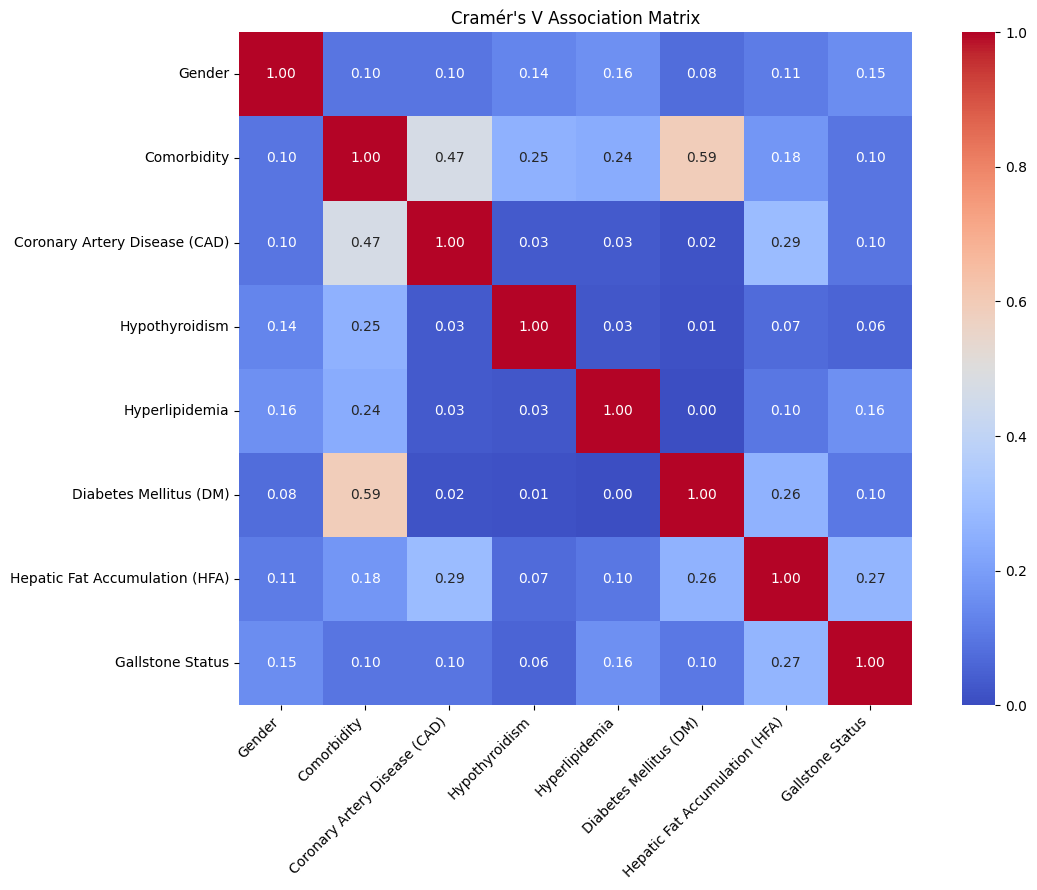

In [ ]:
plt.figure(figsize=(12, 9))

sns.heatmap(
  cramers_matrix,
  annot=True,
  fmt='.2f',
  cmap='coolwarm',
  vmin=0,
  vmax=1,
  square=True
)

plt.title("Cramér's V Association Matrix")
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
# Menghilangkan Gallstone Status dari cat_cols
cat_cols = [col for col in cat_cols if col != 'Gallstone Status']

### Hasil EDA:


## Data Preprocessing


Data Preprocessing dilakukan dengan tahapan sebagai berikut.
1. Membagi DataFrame menjadi Train Set dan Test Set
1. Transformasi Distribusi & Transformasi Log
2. Pembersihan Outlier (Outlier Removal & Capping)
3. Pembersihan Multikolinearitas (Analisis Korelasi & VIF Filter)
4. Encoding & Feature Scaling
5. Seleksi Fitur Berbasis SHAP

### Data Splitting

In [ ]:
X = df.drop(columns=['Gallstone Status'])
y = df['Gallstone Status']

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
  X, y,
  test_size=0.2,
  random_state=42,
  stratify=y
)

In [ ]:
X_train_processed = X_train.copy()
X_test_processed = X_test.copy()

### Outlier Cleaning

In [ ]:
# Capping berdasarkan IQR data training
capping_summary = []

for col in num_cols:
  Q1 = X_train_processed[col].quantile(0.25)
  Q3 = X_train_processed[col].quantile(0.75)
  IQR = Q3 - Q1

  lower = Q1 - 1.5 * IQR
  upper = Q3 + 1.5 * IQR

  outliers_train = (
    (X_train_processed[col] < lower) |
    (X_train_processed[col] > upper)
  ).sum()

  outliers_test = (
    (X_test_processed[col] < lower) |
    (X_test_processed[col] > upper)
  ).sum()

  capping_summary.append({
    'Feature': col,
    'Lower Bound': lower,
    'Upper Bound': upper,
    'Remaining Outliers Train': outliers_train,
    'Remaining Outliers Test': outliers_test
  })

display(pd.DataFrame(capping_summary))

,Feature,Lower Bound,Upper Bound,Remaining Outliers Train,Remaining Outliers Test
0,Age,11.0000,83.0000,2,0
1,Height,135.0000,199.0000,0,0
2,Weight,37.2750,122.6750,2,0
3,Body Mass Index (BMI),15.2500,41.6500,5,0
4,Total Body Water (TBW),14.6250,66.4250,1,0
5,Extracellular Water (ECW),7.9000,26.3000,1,0
6,Intracellular Water (ICW),6.3750,40.5750,1,0
7,Extracellular Fluid/Total Body Water (ECF/TBW),34.1875,49.8875,5,2
8,Total Body Fat Ratio (TBFR) (%),2.7725,54.1125,0,0
9,Lean Mass (LM) (%),45.9275,97.1075,0,0


### Transformasi Distribusi & Normalisasi Log

In [ ]:
# Transformasi Log
skewed_cols = [
  col for col in num_cols
  if col in X_train.columns
  and X_train[col].skew() > 0.5
]

log_cols = [
  col for col in skewed_cols
  if (X_train[col].dropna() >= 0).all()
]

X_train_processed[log_cols] = np.log1p(
  X_train_processed[log_cols]
)

X_test_processed[log_cols] = np.log1p(
  X_test_processed[log_cols]
)

print("Fitur right-skewed:", skewed_cols)
print("Fitur yang ditransformasi log:", log_cols)

Fitur right-skewed: ['Body Mass Index (BMI)', 'Intracellular Water (ICW)', 'Visceral Fat Rating (VFR)', 'Obesity (%)', 'Total Fat Content (TFC)', 'Visceral Fat Area (VFA)', 'Glucose', 'High Density Lipoprotein (HDL)', 'Triglyceride', 'Aspartat Aminotransferaz (AST)', 'Alanin Aminotransferaz (ALT)', 'Alkaline Phosphatase (ALP)', 'Creatinine', 'C-Reactive Protein (CRP)']
Fitur yang ditransformasi log: ['Body Mass Index (BMI)', 'Intracellular Water (ICW)', 'Visceral Fat Rating (VFR)', 'Obesity (%)', 'Total Fat Content (TFC)', 'Visceral Fat Area (VFA)', 'Glucose', 'High Density Lipoprotein (HDL)', 'Triglyceride', 'Aspartat Aminotransferaz (AST)', 'Alanin Aminotransferaz (ALT)', 'Alkaline Phosphatase (ALP)', 'Creatinine', 'C-Reactive Protein (CRP)']


### Multikolinearitas Cleaning

In [ ]:
# Analisis Korelasi Fitur
corr_processed = X_train_processed[num_cols].corr()

# Mencari pasangan fitur dengan korelasi > 0.95
upper = corr_processed.abs().where(
    np.triu(np.ones(corr_processed.shape), k=1).astype(bool)
)

correlation_pairs = []

for col in upper.columns:
  for row in upper.index:
    value = upper.loc[row, col]

    if pd.notna(value) and value > 0.95:
      correlation_pairs.append({
        'Feature 1': row,
        'Feature 2': col,
        'Correlation': value
      })

correlation_df = pd.DataFrame(
  correlation_pairs,
  columns=['Feature 1', 'Feature 2', 'Correlation']
)

print("Pasangan fitur dengan korelasi absolut > 0.95:")
display(correlation_df)

Pasangan fitur dengan korelasi absolut > 0.95:


,Feature 1,Feature 2,Correlation
0,Total Body Fat Ratio (TBFR) (%),Lean Mass (LM) (%),0.997703


In [ ]:
X_vif = X_train_processed[num_cols].copy()

# Hilangkan kolom konstan dari perhitungan VIF
X_vif = X_vif.loc[:, X_vif.nunique() > 1]

vif_df = pd.DataFrame({
  'Feature': X_vif.columns,
  'VIF': [
    variance_inflation_factor(
      X_vif.values, i
    )
    for i in range(X_vif.shape[1])
  ]
})

vif_df = vif_df.replace(
  [np.inf, -np.inf], np.inf
).sort_values('VIF', ascending=False).reset_index(drop=True)

print("Fitur dengan VIF > 10:")
display(vif_df[vif_df['VIF'] > 10])

Fitur dengan VIF > 10:


,Feature,VIF
0,Total Body Fat Ratio (TBFR) (%),345.359010
1,Lean Mass (LM) (%),259.925186
2,Extracellular Water (ECW),134.500174
3,Body Mass Index (BMI),113.971540
4,Weight,91.468746
5,Height,52.715119
6,Intracellular Water (ICW),52.311054
7,Total Body Water (TBW),45.189620
8,Visceral Fat Area (VFA),31.521988
9,Extracellular Fluid/Total Body Water (ECF/TBW),29.735001


In [ ]:
# Fitur dari analisis korelasi
corr_features = set()

for _, row in correlation_df.iterrows():
  corr_features.add(row['Feature 1'])
  corr_features.add(row['Feature 2'])

# Fitur dari analisis VIF
vif_features = set(
  vif_df.loc[vif_df['VIF'] > 10, 'Feature']
)

# Gabungan kandidat fitur
candidate_features = corr_features | vif_features

print("Kandidat fitur dari korelasi:", sorted(corr_features))
print("Kandidat fitur dari VIF:", sorted(vif_features))
print("Gabungan kandidat fitur:", sorted(candidate_features))

Kandidat fitur dari korelasi: ['Lean Mass (LM) (%)', 'Total Body Fat Ratio (TBFR) (%)']
Kandidat fitur dari VIF: ['Body Mass Index (BMI)', 'Extracellular Fluid/Total Body Water (ECF/TBW)', 'Extracellular Water (ECW)', 'Height', 'Intracellular Water (ICW)', 'Lean Mass (LM) (%)', 'Muscle Mass (MM)', 'Total Body Fat Ratio (TBFR) (%)', 'Total Body Water (TBW)', 'Total Fat Content (TFC)', 'Visceral Fat Area (VFA)', 'Visceral Fat Rating (VFR)', 'Weight']
Gabungan kandidat fitur: ['Body Mass Index (BMI)', 'Extracellular Fluid/Total Body Water (ECF/TBW)', 'Extracellular Water (ECW)', 'Height', 'Intracellular Water (ICW)', 'Lean Mass (LM) (%)', 'Muscle Mass (MM)', 'Total Body Fat Ratio (TBFR) (%)', 'Total Body Water (TBW)', 'Total Fat Content (TFC)', 'Visceral Fat Area (VFA)', 'Visceral Fat Rating (VFR)', 'Weight']


In [ ]:
# Fitur yang dihapus berdasarkan analisis korelasi dan VIF
# Fitur yang dihapus berdasarkan paper
features_to_drop = [
  'Total Fat Content (TFC)',
  'Weight',
  'Lean Mass (LM)',
  'Extracellular Water (ECW)'
]

X_train_processed.drop(
  columns=features_to_drop,
  inplace=True,
  errors='ignore'
)

X_test_processed.drop(
  columns=features_to_drop,
  inplace=True,
  errors='ignore'
)

print("X_train:", X_train_processed.shape)
print("X_test:", X_test_processed.shape)

X_train: (255, 35)
X_test: (64, 35)


### Encoding & Feature Scaling

In [ ]:
# Fitur kategorikal ordinal
ordinal_cols = [
  'Hepatic Fat Accumulation (HFA)',
  'Comorbidity'
]

# Fitur kategorikal yang menggunakan OHE
ohe_cols = [col for col in cat_cols if col not in ordinal_cols]


In [ ]:
# Encoder
ohe_encoder = OneHotEncoder(
  drop='if_binary',
  handle_unknown='ignore',
  sparse_output=False
)

ordinal_encoder = OrdinalEncoder(
  handle_unknown='use_encoded_value',
  unknown_value=-1
)

# Gabungkan proses encoding
transformers = []

if ohe_cols:
  transformers.append(('ohe', ohe_encoder, ohe_cols))

if ordinal_cols:
  transformers.append(('ordinal', ordinal_encoder, ordinal_cols))

encoder = ColumnTransformer(
  transformers=transformers,
  remainder='passthrough',
  verbose_feature_names_out=False
)

# Fit pada training, lalu transform training dan testing
X_train_encoded = encoder.fit_transform(X_train_processed)
X_test_encoded = encoder.transform(X_test_processed)

# Ambil nama fitur hasil encoding
feature_names = encoder.get_feature_names_out()

# Ubah hasil menjadi DataFrame
X_train_processed = pd.DataFrame(
  X_train_encoded,
  columns=feature_names,
  index=X_train_processed.index
)

X_test_processed = pd.DataFrame(
  X_test_encoded,
  columns=feature_names,
  index=X_test_processed.index
)

print("X_train:", X_train_processed.shape)
print("X_test:", X_test_processed.shape)

print("\nFitur setelah encoding:")
print(X_train_processed.columns.tolist())

X_train: (255, 35)
X_test: (64, 35)

Fitur setelah encoding:
['Gender_1', 'Coronary Artery Disease (CAD)_1', 'Hypothyroidism_1', 'Hyperlipidemia_1', 'Diabetes Mellitus (DM)_1', 'Hepatic Fat Accumulation (HFA)', 'Comorbidity', 'Age', 'Height', 'Body Mass Index (BMI)', 'Total Body Water (TBW)', 'Intracellular Water (ICW)', 'Extracellular Fluid/Total Body Water (ECF/TBW)', 'Total Body Fat Ratio (TBFR) (%)', 'Lean Mass (LM) (%)', 'Body Protein Content (Protein) (%)', 'Visceral Fat Rating (VFR)', 'Bone Mass (BM)', 'Muscle Mass (MM)', 'Obesity (%)', 'Visceral Fat Area (VFA)', 'Visceral Muscle Area (VMA) (Kg)', 'Glucose', 'Total Cholesterol (TC)', 'Low Density Lipoprotein (LDL)', 'High Density Lipoprotein (HDL)', 'Triglyceride', 'Aspartat Aminotransferaz (AST)', 'Alanin Aminotransferaz (ALT)', 'Alkaline Phosphatase (ALP)', 'Creatinine', 'Glomerular Filtration Rate (GFR)', 'C-Reactive Protein (CRP)', 'Hemoglobin (HGB)', 'Vitamin D']


In [ ]:
# Memperbarui num_cols agar hanya berisi fitur numerik yang masih ada di DataFrame setelah preprocessing
num_cols = [col for col in num_cols if col in X_train_processed.columns]

# Normalisasi Data
scaler = StandardScaler()

X_train_processed[num_cols] = scaler.fit_transform(
  X_train_processed[num_cols]
)

X_test_processed[num_cols] = scaler.transform(
  X_test_processed[num_cols]
)

print("X_train:", X_train_processed.shape)
print("X_test:", X_test_processed.shape)

X_train: (255, 35)
X_test: (64, 35)


### SHAP Feature Selection

25 Fitur Teratas Berdasarkan SHAP:


,Feature,Mean |SHAP|
0,C-Reactive Protein (CRP),1.756389
1,Vitamin D,0.809540
2,Obesity (%),0.589930
3,Extracellular Fluid/Total Body Water (ECF/TBW),0.466439
4,Bone Mass (BM),0.391463
5,Aspartat Aminotransferaz (AST),0.387962
6,Visceral Fat Area (VFA),0.387073
7,Body Protein Content (Protein) (%),0.384449
8,Hemoglobin (HGB),0.275109
9,Visceral Muscle Area (VMA) (Kg),0.268433


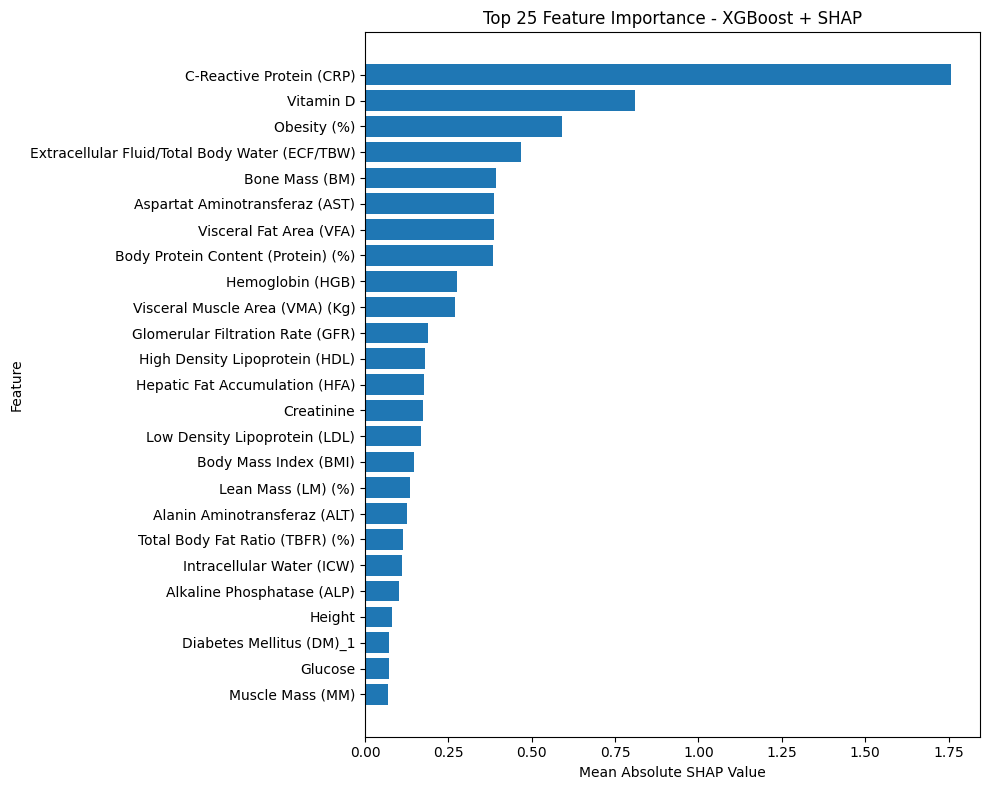

In [ ]:
xgb_model = XGBClassifier(
  n_estimators=200,
  max_depth=6,
  learning_rate=0.1,
  random_state=42,
  eval_metric='logloss'
)

xgb_model.fit(X_train_processed, y_train)

explainer = shap.TreeExplainer(xgb_model)
shap_values = explainer.shap_values(X_train_processed)

# Menangani format SHAP untuk klasifikasi biner
if isinstance(shap_values, list):
  shap_values = shap_values[-1]

if getattr(shap_values, 'ndim', 0) == 3:
  shap_values = shap_values[:, :, -1]

# Menghitung rata-rata absolut nilai SHAP setiap fitur
mean_abs_shap = abs(shap_values).mean(axis=0)

shap_importance = pd.DataFrame({
  'Feature': X_train_processed.columns,
  'Mean |SHAP|': mean_abs_shap
}).sort_values(
  by='Mean |SHAP|',
  ascending=False
).reset_index(drop=True)

# Mengambil 25 fitur teratas
top_25_features = shap_importance.head(25)

print("25 Fitur Teratas Berdasarkan SHAP:")
display(top_25_features)

# Visualisasi 25 fitur teratas
plt.figure(figsize=(10, 8))
plt.barh(
  top_25_features['Feature'][::-1],
  top_25_features['Mean |SHAP|'][::-1]
)
plt.xlabel('Mean Absolute SHAP Value')
plt.ylabel('Feature')
plt.title('Top 25 Feature Importance - XGBoost + SHAP')
plt.tight_layout()
plt.show()

## Modeling

In [ ]:
# Ambil nama 25 fitur teratas dari hasil SHAP
top_features = top_25_features['Feature'].tolist()

# Gunakan fitur yang sama untuk training dan testing
X_train_model = X_train_processed[top_features].copy()
X_test_model = X_test_processed[top_features].copy()

# Pastikan target berbentuk Series
y_train_model = pd.Series(y_train, index=X_train_model.index).squeeze()
y_test_model = pd.Series(y_test, index=X_test_model.index).squeeze()

# Pastikan target klasifikasi biner
if y_train_model.nunique() != 2:
    raise ValueError("Kode ini ditujukan untuk klasifikasi biner.")

# Tangani nilai tak hingga dan nilai kosong jika ada
X_train_model = X_train_model.replace([np.inf, -np.inf], np.nan)
X_test_model = X_test_model.replace([np.inf, -np.inf], np.nan)

# Imputasi menggunakan median dari data training
medians = X_train_model.median()

X_train_model = X_train_model.fillna(medians)
X_test_model = X_test_model.fillna(medians)

# XGBoost dan LightGBM memerlukan target numerik untuk klasifikasi biner
classes = sorted(y_train_model.unique())
class_mapping = {label: i for i, label in enumerate(classes)}

y_train_bin = y_train_model.map(class_mapping).astype(int)
y_test_bin = y_test_model.map(class_mapping)

if y_test_bin.isna().any():
    raise ValueError("Label pada data testing tidak ditemukan di data training.")

y_test_bin = y_test_bin.astype(int)

print("Jumlah fitur:", X_train_model.shape[1])
print("Jumlah data training:", X_train_model.shape[0])
print("Jumlah data testing:", X_test_model.shape[0])
print("Pemetaan kelas:", class_mapping)

Jumlah fitur: 25
Jumlah data training: 255
Jumlah data testing: 64
Pemetaan kelas: {np.int64(0): 0, np.int64(1): 1}


In [ ]:
models = {
  'Random Forest': RandomForestClassifier(
      n_estimators=200,
      random_state=42,
      n_jobs=-1,
      class_weight='balanced'
  ),

  'XGBoost': XGBClassifier(
      n_estimators=200,
      max_depth=4,
      learning_rate=0.05,
      subsample=0.8,
      colsample_bytree=0.8,
      eval_metric='logloss',
      random_state=42,
      n_jobs=-1
  ),

  'Logistic Regression': LogisticRegression(
      max_iter=2000,
      class_weight='balanced',
      random_state=42
  ),

  'Gradient Boosting': GradientBoostingClassifier(
      n_estimators=150,
      learning_rate=0.05,
      max_depth=3,
      random_state=42
  ),

  'Extra Trees': ExtraTreesClassifier(
      n_estimators=200,
      random_state=42,
      n_jobs=-1,
      class_weight='balanced'
  ),

  'LightGBM': LGBMClassifier(
      n_estimators=200,
      learning_rate=0.05,
      verbosity=-1,
      random_state=42,
      n_jobs=-1,
      class_weight='balanced'
  ),

  'SVM RBF': SVC(
      kernel='rbf',
      probability=True,
      class_weight='balanced',
      random_state=42
  )
}

In [ ]:
cv = StratifiedKFold(
  n_splits=5,
  shuffle=True,
  random_state=42
)

fitted_models = {}
cv_auc_scores = {}
results = []

for name, model in models.items():
  print(f"Melatih {name}...")

  # ROC AUC validasi silang pada data training
  scores = cross_val_score(
    clone(model),
    X_train_model,
    y_train_bin,
    cv=cv,
    scoring='roc_auc',
    n_jobs=1
  )

  cv_auc_scores[name] = scores.mean()

  # Latih model menggunakan seluruh data training
  model.fit(X_train_model, y_train_bin)
  fitted_models[name] = model

  # Prediksi data testing
  y_pred = model.predict(X_test_model)
  y_prob = model.predict_proba(X_test_model)[:, 1]

  results.append({
    'Model': name,
    'CV ROC AUC': scores.mean(),
    'Accuracy': accuracy_score(y_test_bin, y_pred),
    'Precision': precision_score(y_test_bin, y_pred, zero_division=0),
    'Recall': recall_score(y_test_bin, y_pred, zero_division=0),
    'F1-score': f1_score(y_test_bin, y_pred, zero_division=0),
    'ROC AUC': roc_auc_score(y_test_bin, y_prob),
    'Brier Score': brier_score_loss(y_test_bin, y_prob)
  })

individual_results = pd.DataFrame(results)

display(
  individual_results.sort_values(
    'ROC AUC',
    ascending=False
  ).reset_index(drop=True).round(4)
)

Melatih Random Forest...
Melatih XGBoost...
Melatih Logistic Regression...
Melatih Gradient Boosting...
Melatih Extra Trees...
Melatih LightGBM...
Melatih SVM RBF...


,Model,CV ROC AUC,Accuracy,Precision,Recall,F1-score,ROC AUC,Brier Score
0,Logistic Regression,0.8465,0.8594,0.8966,0.8125,0.8525,0.9268,0.1081
1,XGBoost,0.8523,0.8438,0.8929,0.7812,0.8333,0.9150,0.1107
2,SVM RBF,0.8403,0.8438,0.8667,0.8125,0.8387,0.9121,0.1227
3,LightGBM,0.8415,0.8438,0.8667,0.8125,0.8387,0.9092,0.1120
4,Extra Trees,0.8488,0.7656,0.7742,0.7500,0.7619,0.8701,0.1588
5,Random Forest,0.8554,0.7969,0.8065,0.7812,0.7937,0.8672,0.1568
6,Gradient Boosting,0.8231,0.7969,0.8276,0.7500,0.7869,0.8604,0.1477


In [ ]:
# Gunakan skor CV sebagai bobot
voting_weights = [
  cv_auc_scores[name]
  for name in models
]

print("Bobot Soft Voting:")
display(pd.DataFrame({
  'Model': list(models.keys()),
  'CV ROC AUC': voting_weights
}).round(4))

soft_voting = VotingClassifier(
  estimators=[
    (name, clone(model))
    for name, model in models.items()
  ],
  voting='soft',
  weights=voting_weights,
  n_jobs=1
)

soft_voting.fit(X_train_model, y_train_bin)

print("Soft Voting selesai dilatih.")

Bobot Soft Voting:


,Model,CV ROC AUC
0,Random Forest,0.8554
1,XGBoost,0.8523
2,Logistic Regression,0.8465
3,Gradient Boosting,0.8231
4,Extra Trees,0.8488
5,LightGBM,0.8415
6,SVM RBF,0.8403


Soft Voting selesai dilatih.


In [ ]:
# Kompatibilitas dengan beberapa versi scikit-learn
try:
  calibrated_ensemble = CalibratedClassifierCV(
    estimator=clone(soft_voting),
    method='sigmoid',
    cv=cv,
    ensemble=True
  )
except TypeError:
  calibrated_ensemble = CalibratedClassifierCV(
    base_estimator=clone(soft_voting),
    method='sigmoid',
    cv=cv
  )

calibrated_ensemble.fit(X_train_model, y_train_bin)

# Prediksi probabilitas yang sudah dikalibrasi
y_prob_calibrated = calibrated_ensemble.predict_proba(
    X_test_model
)[:, 1]

# Ambang keputusan default 0.5
y_pred_calibrated = (y_prob_calibrated >= 0.5).astype(int)

calibrated_result = {
  'Model': 'Calibrated Soft Voting (7 Models)',
  'Accuracy': accuracy_score(y_test_bin, y_pred_calibrated),
  'Precision': precision_score(
    y_test_bin, y_pred_calibrated, zero_division=0
  ),
  'Recall': recall_score(
    y_test_bin, y_pred_calibrated, zero_division=0
  ),
  'F1-score': f1_score(
    y_test_bin, y_pred_calibrated, zero_division=0
  ),
  'ROC AUC': roc_auc_score(y_test_bin, y_prob_calibrated),
  'Brier Score': brier_score_loss(
    y_test_bin, y_prob_calibrated
  )
}

display(pd.DataFrame([calibrated_result]).round(4))

,Model,Accuracy,Precision,Recall,F1-score,ROC AUC,Brier Score
0,Calibrated Soft Voting (7 Models),0.8125,0.8333,0.7812,0.8065,0.9189,0.1185


In [ ]:
stacking_model = StackingClassifier(
    estimators=[
        ('rf', clone(models['Random Forest'])),
        ('xgb', clone(models['XGBoost']))
    ],
    final_estimator=LogisticRegression(
        max_iter=2000,
        random_state=42
    ),
    stack_method='predict_proba',
    cv=cv,
    n_jobs=1,
    passthrough=False
)

stacking_model.fit(X_train_model, y_train_bin)

y_pred_stacking = stacking_model.predict(X_test_model)
y_prob_stacking = stacking_model.predict_proba(X_test_model)[:, 1]

stacking_result = {
    'Model': 'Stacking (RF + XGBoost + LR)',
    'Accuracy': accuracy_score(y_test_bin, y_pred_stacking),
    'Precision': precision_score(
        y_test_bin, y_pred_stacking, zero_division=0
    ),
    'Recall': recall_score(
        y_test_bin, y_pred_stacking, zero_division=0
    ),
    'F1-score': f1_score(
        y_test_bin, y_pred_stacking, zero_division=0
    ),
    'ROC AUC': roc_auc_score(y_test_bin, y_prob_stacking),
    'Brier Score': brier_score_loss(y_test_bin, y_prob_stacking)
}

display(pd.DataFrame([stacking_result]).round(4))

,Model,Accuracy,Precision,Recall,F1-score,ROC AUC,Brier Score
0,Stacking (RF + XGBoost + LR),0.8281,0.8621,0.7812,0.8197,0.9121,0.1234


In [ ]:
three_model_names = [
    'Random Forest',
    'XGBoost',
    'Logistic Regression'
]

three_model_voting = VotingClassifier(
    estimators=[
        (name, clone(models[name]))
        for name in three_model_names
    ],
    voting='soft',
    weights=[
        cv_auc_scores[name]
        for name in three_model_names
    ],
    n_jobs=1
)

three_model_voting.fit(X_train_model, y_train_bin)

y_pred_three = three_model_voting.predict(X_test_model)
y_prob_three = three_model_voting.predict_proba(X_test_model)[:, 1]

three_voting_result = {
    'Model': 'Soft Voting (3 Models)',
    'Accuracy': accuracy_score(y_test_bin, y_pred_three),
    'Precision': precision_score(
        y_test_bin, y_pred_three, zero_division=0
    ),
    'Recall': recall_score(
        y_test_bin, y_pred_three, zero_division=0
    ),
    'F1-score': f1_score(
        y_test_bin, y_pred_three, zero_division=0
    ),
    'ROC AUC': roc_auc_score(y_test_bin, y_prob_three),
    'Brier Score': brier_score_loss(y_test_bin, y_prob_three)
}

display(pd.DataFrame([three_voting_result]).round(4))

,Model,Accuracy,Precision,Recall,F1-score,ROC AUC,Brier Score
0,Soft Voting (3 Models),0.8594,0.8966,0.8125,0.8525,0.9287,0.1149


In [ ]:
age_candidates = ['Age', 'age']
bmi_candidates = ['BMI', 'Body Mass Index', 'bmi']

age_col = next(
    (col for col in age_candidates if col in X_train_processed.columns),
    None
)

bmi_col = next(
    (col for col in bmi_candidates if col in X_train_processed.columns),
    None
)

baseline_result = None

if age_col is not None and bmi_col is not None:
    baseline_cols = [age_col, bmi_col]

    X_train_baseline = X_train_processed[baseline_cols].copy()
    X_test_baseline = X_test_processed[baseline_cols].copy()

    baseline_medians = X_train_baseline.median()

    X_train_baseline = X_train_baseline.replace(
        [np.inf, -np.inf], np.nan
    ).fillna(baseline_medians)

    X_test_baseline = X_test_baseline.replace(
        [np.inf, -np.inf], np.nan
    ).fillna(baseline_medians)

    baseline_lr = LogisticRegression(
        max_iter=2000,
        random_state=42
    )

    baseline_lr.fit(X_train_baseline, y_train_bin)

    y_pred_baseline = baseline_lr.predict(X_test_baseline)
    y_prob_baseline = baseline_lr.predict_proba(X_test_baseline)[:, 1]

    baseline_result = {
        'Model': 'Baseline Logistic Regression (Age + BMI)',
        'Accuracy': accuracy_score(y_test_bin, y_pred_baseline),
        'Precision': precision_score(
            y_test_bin, y_pred_baseline, zero_division=0
        ),
        'Recall': recall_score(
            y_test_bin, y_pred_baseline, zero_division=0
        ),
        'F1-score': f1_score(
            y_test_bin, y_pred_baseline, zero_division=0
        ),
        'ROC AUC': roc_auc_score(y_test_bin, y_prob_baseline),
        'Brier Score': brier_score_loss(y_test_bin, y_prob_baseline)
    }

    display(pd.DataFrame([baseline_result]).round(4))

else:
    print(
        "Baseline dilewati: kolom Age dan/atau BMI tidak ditemukan. "
        "Periksa nama kolom pada X_train_processed."
    )

Baseline dilewati: kolom Age dan/atau BMI tidak ditemukan. Periksa nama kolom pada X_train_processed.


Perbandingan seluruh model:


,Model,Accuracy,Precision,Recall,F1-score,ROC AUC,Brier Score
0,Soft Voting (3 Models),0.8594,0.8966,0.8125,0.8525,0.9287,0.1149
1,Logistic Regression,0.8594,0.8966,0.8125,0.8525,0.9268,0.1081
2,Calibrated Soft Voting (7 Models),0.8125,0.8333,0.7812,0.8065,0.9189,0.1185
3,XGBoost,0.8438,0.8929,0.7812,0.8333,0.9150,0.1107
4,Stacking (RF + XGBoost + LR),0.8281,0.8621,0.7812,0.8197,0.9121,0.1234
5,SVM RBF,0.8438,0.8667,0.8125,0.8387,0.9121,0.1227
6,LightGBM,0.8438,0.8667,0.8125,0.8387,0.9092,0.1120
7,Extra Trees,0.7656,0.7742,0.7500,0.7619,0.8701,0.1588
8,Random Forest,0.7969,0.8065,0.7812,0.7937,0.8672,0.1568
9,Gradient Boosting,0.7969,0.8276,0.7500,0.7869,0.8604,0.1477


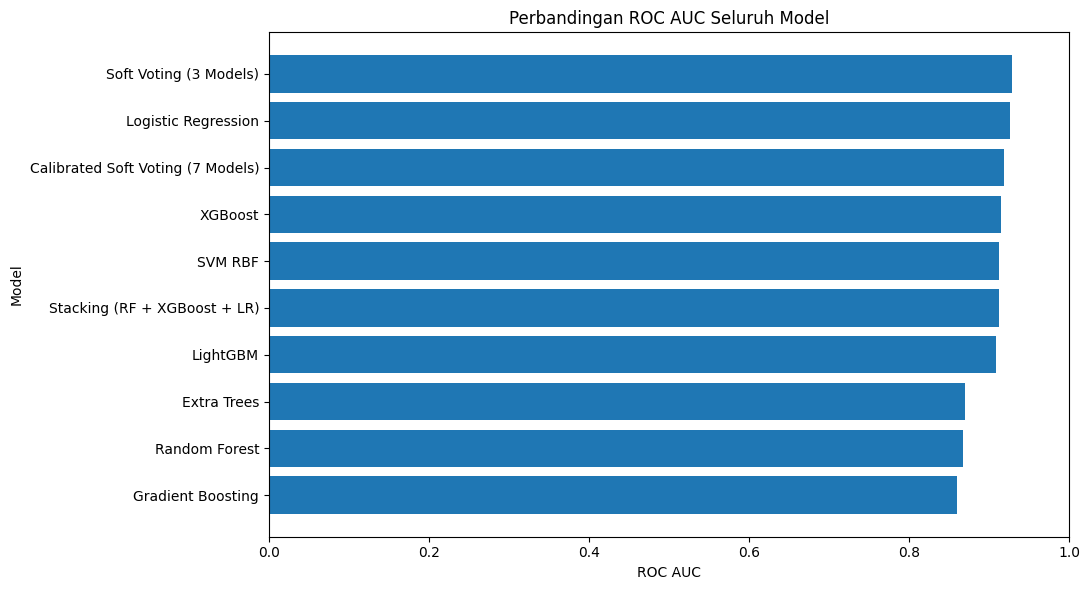

In [ ]:
comparison_results = individual_results.drop(
    columns=['CV ROC AUC']
).to_dict('records')

comparison_results.extend([
    calibrated_result,
    stacking_result,
    three_voting_result
])

if baseline_result is not None:
    comparison_results.append(baseline_result)

comparison_df = pd.DataFrame(comparison_results)

comparison_df = comparison_df.sort_values(
    by='ROC AUC',
    ascending=False
).reset_index(drop=True)

print("Perbandingan seluruh model:")
display(comparison_df.round(4))

# Visualisasi ROC AUC
plt.figure(figsize=(11, 6))

plot_df = comparison_df.sort_values('ROC AUC')

plt.barh(
    plot_df['Model'],
    plot_df['ROC AUC']
)

plt.xlabel('ROC AUC')
plt.ylabel('Model')
plt.title('Perbandingan ROC AUC Seluruh Model')
plt.xlim(0, 1)
plt.tight_layout()
plt.show()

Classification Report:
              precision    recall  f1-score   support

           0       0.79      0.84      0.82        32
           1       0.83      0.78      0.81        32

    accuracy                           0.81        64
   macro avg       0.81      0.81      0.81        64
weighted avg       0.81      0.81      0.81        64



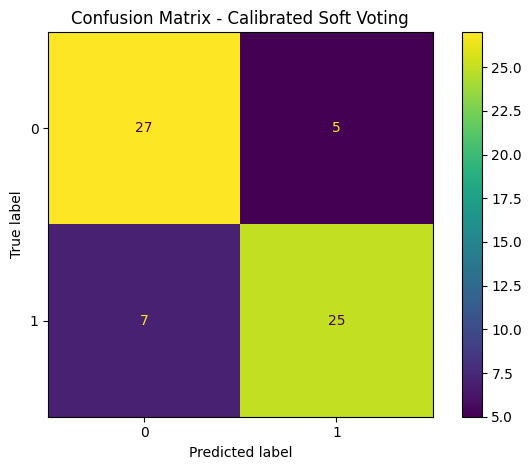

In [ ]:
print("Classification Report:")
print(
    classification_report(
        y_test_bin,
        y_pred_calibrated,
        target_names=[str(c) for c in classes],
        zero_division=0
    )
)

cm = confusion_matrix(y_test_bin, y_pred_calibrated)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[str(c) for c in classes]
)

disp.plot()
plt.title('Confusion Matrix - Calibrated Soft Voting')
plt.tight_layout()
plt.show()